# AutismCare: Predicting the Age of Autism Diagnosis

**Mission:** help parents of autistic children get an early diagnosis and connect them to qualified professionals and therapists.

**Use case:** many autistic children are diagnosed years after the first signs. This model predicts the age at which a child is diagnosed with autism.
Outreach teams use it to contact families at risk of a late diagnosis first.

| | |
|---|---|
| Target (y) | Age at autism diagnosis, in years |
| Users | Outreach teams and parents |
| Data | NSCH 2022 and 2024, from the [US Census Bureau](https://www.census.gov/programs-surveys/nsch/data/datasets.html) |
| Success metric | Test RMSE at least 15% below a baseline that always predicts the mean |

## 1. Setup

In [1]:
import io
import zipfile
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the data
We download the NSCH 2022 and 2024 survey files and keep only children whose parent was told they have autism.

In [2]:
NSCH_URLS = {
    2022: "https://www2.census.gov/programs-surveys/nsch/datasets/2022/nsch_2022_topical_Stata.zip",
    2024: "https://www2.census.gov/programs-surveys/nsch/datasets/2024/nsch_2024_topical_Stata.zip",
}

RAW_COLUMNS = [
    "HHID",            # household ID (used only to check for duplicate children)
    "K2Q35A_1_YEARS",  # TARGET: age when first told the child had autism (years)
    "K2Q35C",          # autism severity: 1 mild, 2 moderate, 3 severe
    "K2Q31A",          # ever told: ADHD
    "K2Q33A",          # ever told: anxiety
    "K2Q32A",          # ever told: depression
    "K2Q36A",          # ever told: developmental delay
    "K2Q37A",          # ever told: speech or other language disorder
    "K2Q60A",          # ever told: intellectual disability
    "SC_SEX",          # child's sex
    "SC_RACE_R",       # child's race
    "SC_HISPANIC_R",   # child's Hispanic origin
    "FPL_I1",          # family income as % of the federal poverty line (50 to 400)
    "TOTKIDS_R",       # number of children in the household (1 to 4+)
    "INSTYPE",         # health insurance type
    "HIGRADE",         # highest education of the adults in the household
    "HHLANGUAGE",      # main language spoken at home
    "FAMILY_R",        # family structure
    "SC_AGE_YEARS",    # child's age at the time of the survey
]


def load_nsch_year(year, url):
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(request, timeout=180) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    dta_name = next(name for name in archive.namelist() if name.endswith(".dta"))
    survey = pd.read_stata(archive.open(dta_name), convert_categoricals=False)
    survey.columns = survey.columns.str.upper()
    autism = survey[survey["K2Q35A"] == 1]
    print(f"{year}: {len(survey):,} children surveyed, {len(autism):,} ever told they have autism")
    return autism[RAW_COLUMNS].assign(SURVEY_YEAR=year)


raw = pd.concat([load_nsch_year(year, url) for year, url in NSCH_URLS.items()], ignore_index=True)
print("Combined:", raw.shape)

2022: 54,103 children surveyed, 1,908 ever told they have autism


2024: 51,375 children surveyed, 2,352 ever told they have autism
Combined: (4260, 20)


### Making the columns readable
Survey codes are replaced with readable names and labels from the NSCH codebook. Skipped or refused answers become missing values.

In [3]:
YES_NO = {1: "yes", 2: "no"}
RACE = {1: "white", 2: "black", 3: "other", 4: "asian", 5: "other", 7: "multiracial"}

df = pd.DataFrame({
    "diagnosis_age": raw["K2Q35A_1_YEARS"],
    "severity": raw["K2Q35C"].map({1: "mild", 2: "moderate", 3: "severe"}),
    "adhd": raw["K2Q31A"].map(YES_NO),
    "anxiety": raw["K2Q33A"].map(YES_NO),
    "depression": raw["K2Q32A"].map(YES_NO),
    "developmental_delay": raw["K2Q36A"].map(YES_NO),
    "speech_disorder": raw["K2Q37A"].map(YES_NO),
    "intellectual_disability": raw["K2Q60A"].map(YES_NO),
    "sex": raw["SC_SEX"].map({1: "male", 2: "female"}),
    "race_ethnicity": np.where(raw["SC_HISPANIC_R"] == 1, "hispanic", raw["SC_RACE_R"].map(RACE)),
    "income_poverty_ratio": raw["FPL_I1"],
    "num_children": raw["TOTKIDS_R"],
    "insurance_type": raw["INSTYPE"].map({1: "public", 2: "private", 3: "public_and_private", 5: "uninsured"}),
    "parent_education": raw["HIGRADE"].map({1: "less_than_high_school", 2: "high_school", 3: "more_than_high_school"}),
    "home_language": raw["HHLANGUAGE"].map({1: "english", 2: "spanish", 3: "other"}),
    "family_structure": raw["FAMILY_R"].map({1: "two_parents", 2: "two_parents", 3: "two_parents", 4: "two_parents",
                                             5: "single_mother", 6: "single_father", 7: "grandparents", 8: "other"}),
    "current_age": raw["SC_AGE_YEARS"],
    "survey_year": raw["SURVEY_YEAR"],
    "household_id": raw["HHID"],
})
df["race_ethnicity"] = df["race_ethnicity"].replace("nan", np.nan)

print("Shape:", df.shape)
df.head()

Shape: (4260, 19)


,diagnosis_age,severity,adhd,anxiety,depression,developmental_delay,speech_disorder,intellectual_disability,sex,race_ethnicity,income_poverty_ratio,num_children,insurance_type,parent_education,home_language,family_structure,current_age,survey_year,household_id
0,3.0,moderate,no,no,no,yes,yes,no,female,white,92,3,public_and_private,more_than_high_school,english,two_parents,9,2022,22000329
1,4.0,moderate,no,no,NaN,yes,yes,no,male,asian,309,3,private,more_than_high_school,english,two_parents,4,2022,22000397
2,5.0,NaN,yes,yes,no,no,no,no,male,white,400,1,private,more_than_high_school,english,two_parents,8,2022,22000423
3,5.0,mild,no,no,no,yes,yes,no,female,white,400,3,private,more_than_high_school,english,two_parents,6,2022,22001191
4,5.0,mild,yes,no,no,no,no,no,male,white,134,3,private,more_than_high_school,english,NaN,11,2022,22001291


## 3. Inspect the data

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4260 entries, 0 to 4259
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis_age            3975 non-null   float64
 1   severity                 3986 non-null   str    
 2   adhd                     4256 non-null   str    
 3   anxiety                  4233 non-null   str    
 4   depression               4233 non-null   str    
 5   developmental_delay      4240 non-null   str    
 6   speech_disorder          4244 non-null   str    
 7   intellectual_disability  4249 non-null   str    
 8   sex                      4260 non-null   str    
 9   race_ethnicity           4260 non-null   str    
 10  income_poverty_ratio     4260 non-null   int16  
 11  num_children             4260 non-null   int8   
 12  insurance_type           4203 non-null   str    
 13  parent_education         4260 non-null   str    
 14  home_language            4229 non-n

In [5]:
df.describe()

,diagnosis_age,income_poverty_ratio,num_children,current_age,survey_year,household_id
count,3975.000000,4260.000000,4260.000000,4260.000000,4260.000000,4.260000e+03
mean,5.291824,263.792723,1.773709,10.395070,2023.104225,2.328814e+07
std,3.639570,129.694456,0.861895,4.487286,0.994670,1.006379e+06
min,1.000000,50.000000,1.000000,0.000000,2022.000000,2.200033e+07
25%,3.000000,145.000000,1.000000,7.000000,2022.000000,2.219688e+07
50%,4.000000,279.500000,2.000000,11.000000,2024.000000,2.403744e+07
75%,7.000000,400.000000,2.000000,14.000000,2024.000000,2.420797e+07
max,15.000000,400.000000,4.000000,17.000000,2024.000000,2.437404e+07


In [6]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate children (same household ID and survey year):",
      df.duplicated(subset=["household_id", "survey_year"]).sum())

Missing values per column:
diagnosis_age              285
severity                   274
adhd                         4
anxiety                     27
depression                  27
developmental_delay         20
speech_disorder             16
intellectual_disability     11
sex                          0
race_ethnicity               0
income_poverty_ratio         0
num_children                 0
insurance_type              57
parent_education             0
home_language               31
family_structure            91
current_age                  0
survey_year                  0
household_id                 0
dtype: int64

Duplicate children (same household ID and survey year): 0


In [7]:
print("Rows without a diagnosis age:", df["diagnosis_age"].isnull().sum())
df = df.dropna(subset=["diagnosis_age"]).reset_index(drop=True)
print("Rows kept:", len(df))

Rows without a diagnosis age: 285
Rows kept: 3975


**Observations**
1. 285 children have no diagnosis age and are removed, leaving 3,975 rows.
2. Most columns are categorical, so they need encoding.
3. A few columns have missing values; the pipeline fills them.
4. There are no duplicate children.
5. Income is limited to 50 to 400% of the poverty line.

## 4. Visualizations
### 4.1 Target: age at autism diagnosis

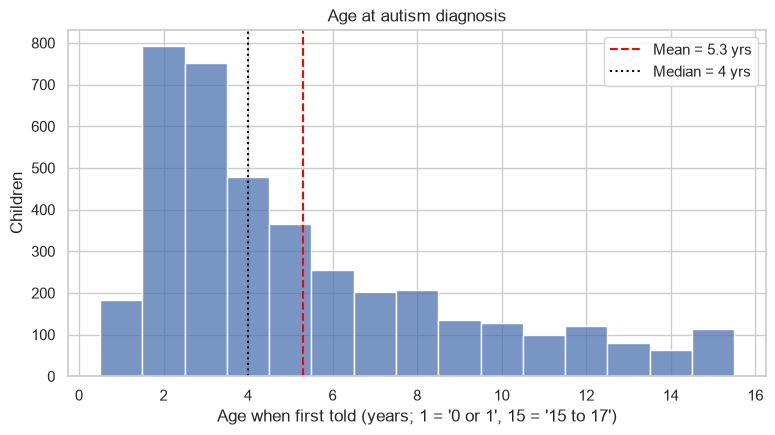

count    3975.00
mean        5.29
std         3.64
min         1.00
25%         3.00
50%         4.00
75%         7.00
max        15.00
Name: diagnosis_age, dtype: float64


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df["diagnosis_age"], bins=np.arange(0.5, 16.5, 1), ax=ax, color="#4C72B0")
ax.axvline(df["diagnosis_age"].mean(), color="red", linestyle="--", label=f"Mean = {df['diagnosis_age'].mean():.1f} yrs")
ax.axvline(df["diagnosis_age"].median(), color="black", linestyle=":", label=f"Median = {df['diagnosis_age'].median():.0f} yrs")
ax.set(title="Age at autism diagnosis", xlabel="Age when first told (years; 1 = '0 or 1', 15 = '15 to 17')", ylabel="Children")
ax.legend()
plt.show()

print(df["diagnosis_age"].describe().round(2))

**What it shows:** Most children are diagnosed at 2 to 4 years (median 4). A long tail reaches the teenage years.

**What we decided:** Keep the target in years, so errors are easy to read. Keep the late diagnoses, because they are the children our users need to find.

### 4.2 Correlation heatmap
Yes/no answers are coded as 1/0 for this plot only. Current age is included to check for leakage.

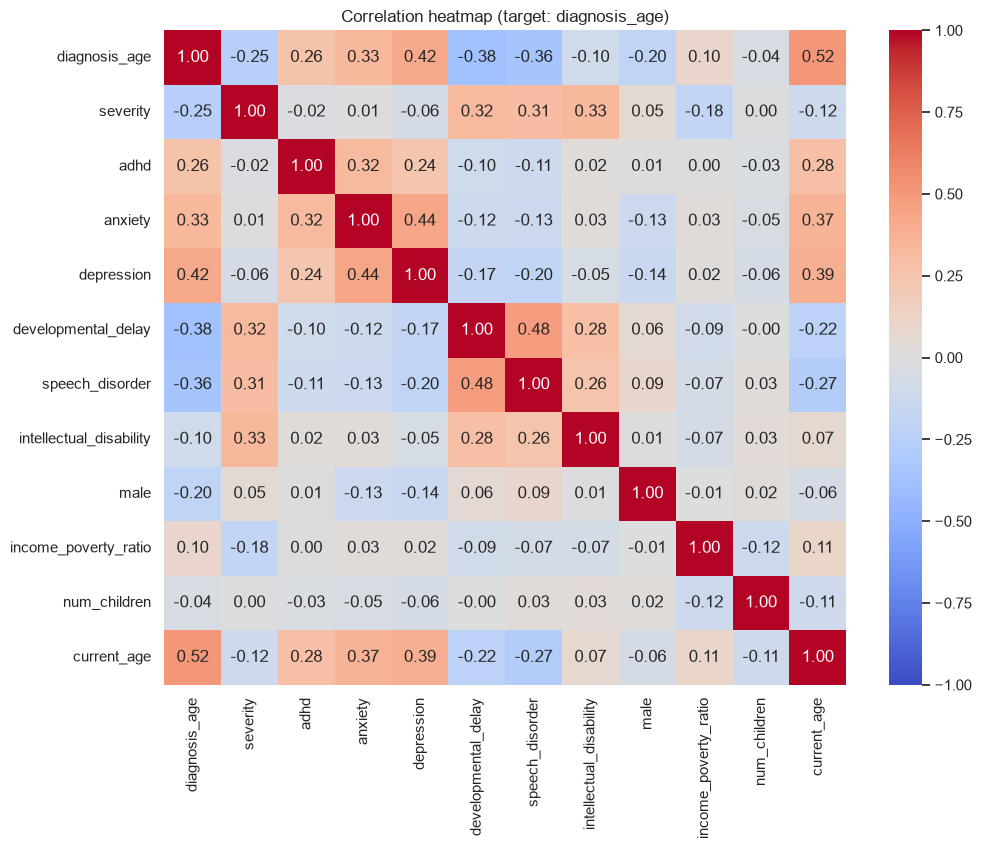

Correlation with diagnosis_age:
current_age                0.515
depression                 0.417
developmental_delay       -0.382
speech_disorder           -0.358
anxiety                    0.334
adhd                       0.265
severity                  -0.253
male                      -0.197
intellectual_disability   -0.101
income_poverty_ratio       0.095
num_children              -0.041
Name: diagnosis_age, dtype: float64


In [9]:
numeric_view = pd.DataFrame({
    "diagnosis_age": df["diagnosis_age"],
    "severity": df["severity"].map({"mild": 1, "moderate": 2, "severe": 3}),
    "adhd": df["adhd"].map({"yes": 1, "no": 0}),
    "anxiety": df["anxiety"].map({"yes": 1, "no": 0}),
    "depression": df["depression"].map({"yes": 1, "no": 0}),
    "developmental_delay": df["developmental_delay"].map({"yes": 1, "no": 0}),
    "speech_disorder": df["speech_disorder"].map({"yes": 1, "no": 0}),
    "intellectual_disability": df["intellectual_disability"].map({"yes": 1, "no": 0}),
    "male": (df["sex"] == "male").astype(int),
    "income_poverty_ratio": df["income_poverty_ratio"],
    "num_children": df["num_children"],
    "current_age": df["current_age"],
})

corr = numeric_view.corr()
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation heatmap (target: diagnosis_age)")
plt.show()

print("Correlation with diagnosis_age:")
print(corr["diagnosis_age"].drop("diagnosis_age").sort_values(key=abs, ascending=False).round(3))

**What it shows:** Other conditions matter most. Developmental delay and speech disorder go with earlier diagnosis, and ADHD and anxiety with later diagnosis. Current age has the highest correlation (+0.52).

**What we decided:** Keep the conditions, severity and sex. Check current age for leakage. Drop the number of children.

### 4.3 Average diagnosis age by group

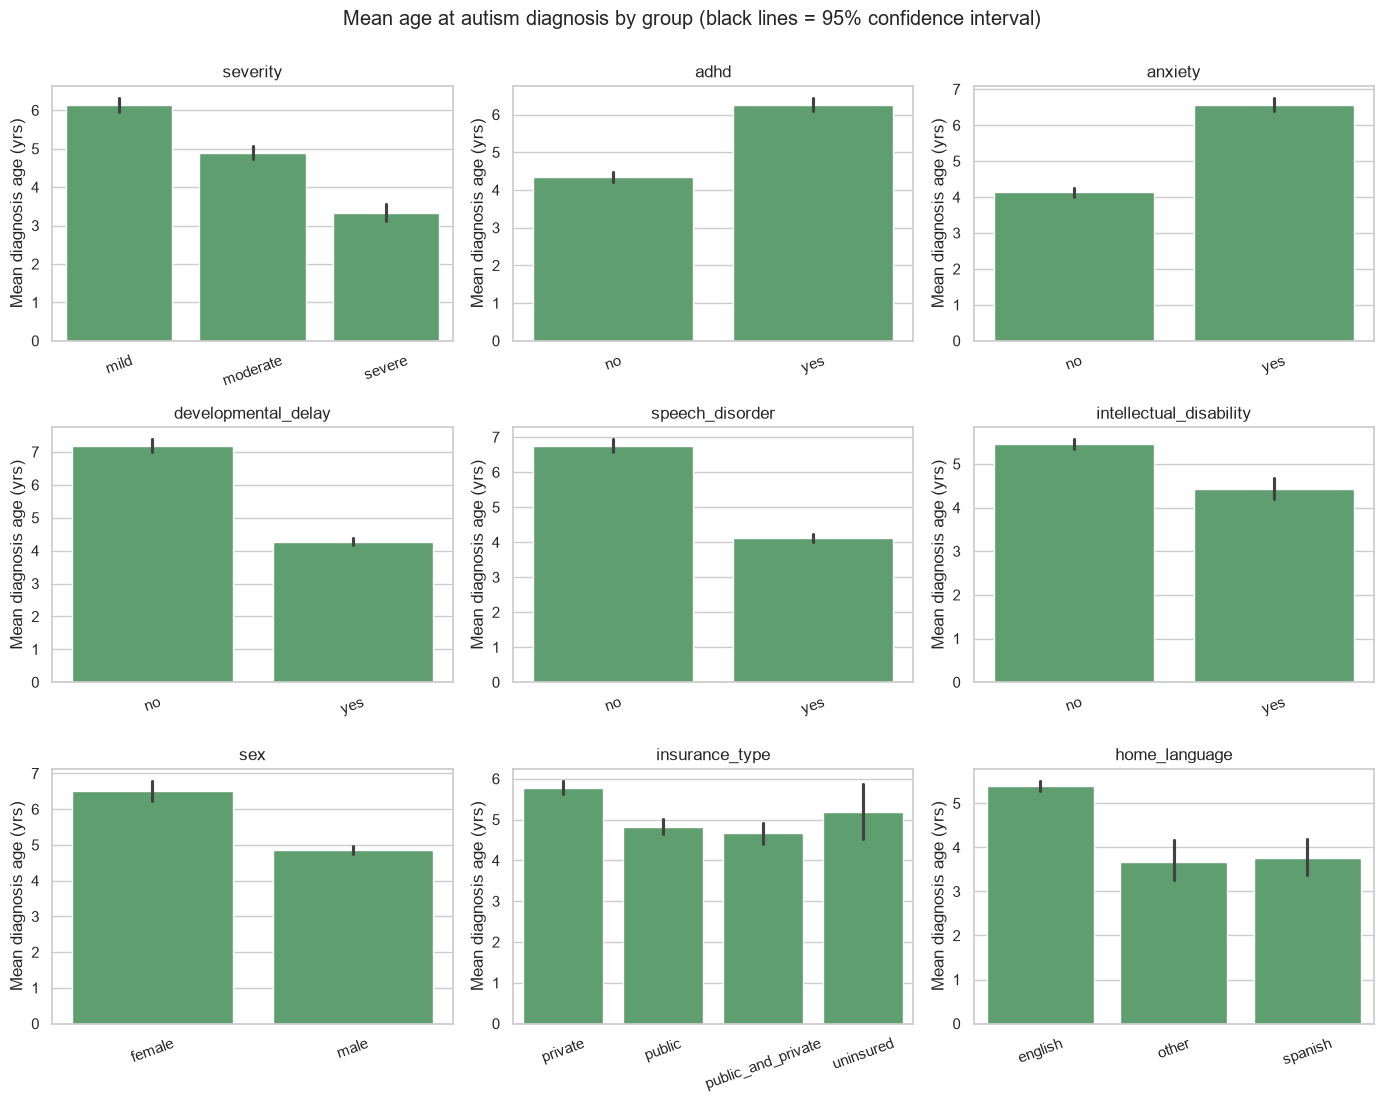

In [10]:
group_columns = ["severity", "adhd", "anxiety", "developmental_delay", "speech_disorder",
                 "intellectual_disability", "sex", "insurance_type", "home_language"]

fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, column in zip(axes.ravel(), group_columns):
    order = sorted(df[column].dropna().unique())
    sns.barplot(data=df, x=column, y="diagnosis_age", order=order, ax=ax, color="#55A868", errorbar=("ci", 95))
    ax.set(title=column, xlabel="", ylabel="Mean diagnosis age (yrs)")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Mean age at autism diagnosis by group (black lines = 95% confidence interval)", y=1.0)
plt.tight_layout()
plt.show()

**What it shows:** ADHD and anxiety go with diagnosis about 2 years later. Developmental delay and speech disorder go with diagnosis 2.5 to 3 years earlier. Girls and children with mild autism are diagnosed later.

**What we decided:** Keep all nine features. Insurance and language stay because access to care is part of our mission.

### 4.4 Numeric features

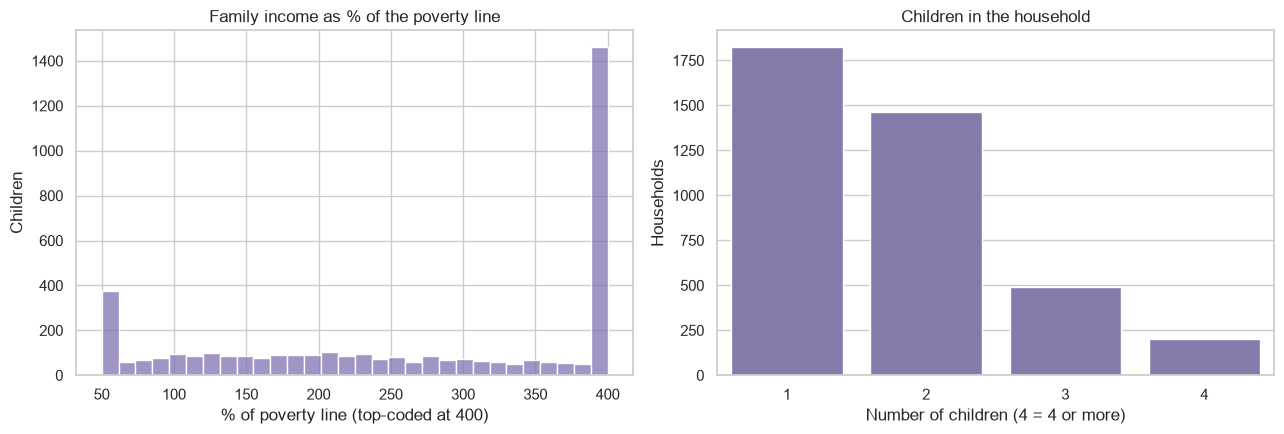

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["income_poverty_ratio"], bins=30, ax=axes[0], color="#8172B2")
axes[0].set(title="Family income as % of the poverty line", xlabel="% of poverty line (top-coded at 400)", ylabel="Children")
sns.countplot(x=df["num_children"], ax=axes[1], color="#8172B2")
axes[1].set(title="Children in the household", xlabel="Number of children (4 = 4 or more)", ylabel="Households")
plt.tight_layout()
plt.show()

**What it shows:** Income is capped at 400% and floored at 50% of the poverty line. Most homes have 1 or 2 children.

**What we decided:** Standardize income, because its large scale would dominate gradient descent. Drop the number of children (correlation -0.04).

## 5. Feature engineering
### 5.1 Leakage check
A child cannot be diagnosed older than they are now, so current age may leak the answer.

In [12]:
print("Correlation of current_age with diagnosis_age:", round(df["current_age"].corr(df["diagnosis_age"]), 3))
print("\nMean current age (years) of children with and without each condition:")
condition_columns = ["adhd", "anxiety", "depression", "developmental_delay", "speech_disorder", "intellectual_disability"]
print(pd.DataFrame({col: df.groupby(col)["current_age"].mean() for col in condition_columns}).T.round(1))

Correlation of current_age with diagnosis_age: 0.515

Mean current age (years) of children with and without each condition:
                           no   yes
adhd                      9.1  11.6
anxiety                   8.8  12.1
depression                9.5  13.8
developmental_delay      11.7   9.6
speech_disorder          11.7   9.3
intellectual_disability  10.2  11.0


**Result:** Current age correlates +0.52 with the target only because older children are the only ones who can have late diagnoses. `current_age` is therefore dropped.

Children with depression are 13.8 years old on average, so depression also signals age. `depression` is also dropped. ADHD and anxiety are kept, because they are known reasons for late diagnosis.

### 5.2 Columns dropped and features kept

In [13]:
NUMERIC_FEATURES = ["income_poverty_ratio"]
CATEGORICAL_FEATURES = ["severity", "adhd", "anxiety", "developmental_delay", "speech_disorder",
                        "intellectual_disability", "sex", "insurance_type", "home_language"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "diagnosis_age"

dropped = [col for col in df.columns if col not in FEATURES + [TARGET]]
print("Dropped columns:", dropped)
print(f"Kept {len(FEATURES)} input features:", FEATURES)

Dropped columns: ['depression', 'race_ethnicity', 'num_children', 'parent_education', 'family_structure', 'current_age', 'survey_year', 'household_id']
Kept 10 input features: ['income_poverty_ratio', 'severity', 'adhd', 'anxiety', 'developmental_delay', 'speech_disorder', 'intellectual_disability', 'sex', 'insurance_type', 'home_language']


Cross-validation on the training rows confirms these choices.

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

train_rows, _ = train_test_split(df.index, test_size=0.2, random_state=RANDOM_STATE)
check = df.loc[train_rows]


def cv_rmse(numeric, categorical):
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ])
    model = Pipeline([("prep", prep), ("model", LinearRegression())])
    scores = cross_val_score(model, check[numeric + categorical], check[TARGET], cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean()


feature_sets = {
    "Baseline: always predict the mean": None,
    "Kept 10 features": (NUMERIC_FEATURES, CATEGORICAL_FEATURES),
    "Kept + race, education, family, num_children": (NUMERIC_FEATURES + ["num_children"],
                                                    CATEGORICAL_FEATURES + ["race_ethnicity", "parent_education", "family_structure"]),
    "Kept + depression (age proxy)": (NUMERIC_FEATURES, CATEGORICAL_FEATURES + ["depression"]),
    "Kept + current_age (leakage)": (NUMERIC_FEATURES + ["current_age"], CATEGORICAL_FEATURES),
}
results = {name: (check[TARGET].std(ddof=0) if cols is None else cv_rmse(*cols)) for name, cols in feature_sets.items()}
pd.Series(results, name="CV RMSE (years)").round(3).to_frame()

,CV RMSE (years)
Baseline: always predict the mean,3.674
Kept 10 features,3.059
"Kept + race, education, family, num_children",3.070
Kept + depression (age proxy),2.956
Kept + current_age (leakage),2.834


**Result of the check:** The 10 kept features cut the error from 3.67 to 3.06 years (17%). Extra columns made it slightly worse. Current age and depression helped only because they reveal age.

**Columns dropped and why**

| Column | Reason |
|---|---|
| 450+ other survey columns | Not related to the use case |
| `current_age` | Leakage (Section 5.1) |
| `depression` | Signals current age |
| `num_children` | No relationship (-0.04) |
| `race_ethnicity`, `parent_education`, `family_structure` | No accuracy gain; race could add bias |
| `survey_year`, `household_id` | Identifiers |

**Features that matter most:** developmental delay, speech disorder, anxiety, ADHD, severity and sex.

## 6. Encode, split and standardize
The data is split 80/20 before any preprocessing. Missing values are filled, categories are one-hot encoded, and all columns are standardized.
The preprocessor is fitted on the training set only.

In [15]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ("scale", StandardScaler()),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
])

X_train_t = preprocessor.fit_transform(X_train)   # learn medians, categories, means and stds from TRAIN only
X_test_t = preprocessor.transform(X_test)         # apply them to TEST without refitting

print("Train rows:", X_train.shape[0], " Test rows:", X_test.shape[0])
print("Model inputs after one-hot encoding:", X_train_t.shape[1])
print(list(preprocessor.get_feature_names_out()))
print("\nTrain means (should be ~0):", X_train_t.mean(axis=0).round(2))
print("Train stds  (should be ~1):", X_train_t.std(axis=0).round(2))

Train rows: 3180  Test rows: 795
Model inputs after one-hot encoding: 23
['num__income_poverty_ratio', 'cat__severity_mild', 'cat__severity_moderate', 'cat__severity_severe', 'cat__adhd_no', 'cat__adhd_yes', 'cat__anxiety_no', 'cat__anxiety_yes', 'cat__developmental_delay_no', 'cat__developmental_delay_yes', 'cat__speech_disorder_no', 'cat__speech_disorder_yes', 'cat__intellectual_disability_no', 'cat__intellectual_disability_yes', 'cat__sex_female', 'cat__sex_male', 'cat__insurance_type_private', 'cat__insurance_type_public', 'cat__insurance_type_public_and_private', 'cat__insurance_type_uninsured', 'cat__home_language_english', 'cat__home_language_other', 'cat__home_language_spanish']

Train means (should be ~0): [ 0. -0. -0.  0. -0.  0. -0.  0. -0.  0. -0.  0. -0.  0.  0. -0. -0.  0.
  0. -0.  0. -0. -0.]
Train stds  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


**Summary of the prepared data**
3,180 training rows and 795 test rows. The 10 features became 23 model inputs. Training columns now have mean 0 and standard deviation 1.

## 7. Linear regression by gradient descent (SGDRegressor)
We train with `partial_fit` in a loop and record the MSE after every epoch.

### 7.1 Tuning
We tune the learning rate, regularization strength and number of epochs. A validation set keeps the test set unseen.

In [16]:
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

X_fit, X_val, y_fit, y_val = train_test_split(X_train_t, y_train.to_numpy(), test_size=0.2, random_state=RANDOM_STATE)
print("Tuning rows:", len(y_fit), " Validation rows:", len(y_val))


def safe_mse(y_true, y_pred):
    """MSE, or infinity if the model has diverged (predictions too large to score)."""
    if not np.all(np.isfinite(y_pred)) or np.abs(y_pred).max() > 1e6:
        return np.inf
    return mean_squared_error(y_true, y_pred)


def train_sgd(X_tr, y_tr, X_ev, y_ev, eta0, alpha, epochs):
    """Train SGDRegressor with partial_fit, one epoch per loop, recording train and evaluation MSE after each epoch."""
    model = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty="l2", random_state=RANDOM_STATE)
    rng = np.random.default_rng(RANDOM_STATE)
    y_tr = np.asarray(y_tr)
    train_hist, eval_hist = [], []
    for _ in range(epochs):
        order = rng.permutation(len(y_tr))          # shuffle the rows every epoch
        model.partial_fit(X_tr[order], y_tr[order])
        train_hist.append(safe_mse(y_tr, model.predict(X_tr)))
        eval_hist.append(safe_mse(y_ev, model.predict(X_ev)))
        if not np.isfinite(eval_hist[-1]):          # stop if training diverged
            break
    return model, train_hist, eval_hist

Tuning rows: 2544  Validation rows: 636


In [17]:
LEARNING_RATES = [0.0001, 0.001, 0.01, 0.1]
ALPHAS = [0.0001, 0.001, 0.01, 0.1, 1.0]
MAX_EPOCHS = 200
EPOCH_CHECKPOINTS = [5, 10, 25, 50, 100, 200]

tuning_rows, histories = [], {}
for eta0 in LEARNING_RATES:
    for alpha in ALPHAS:
        _, train_hist, val_hist = train_sgd(X_fit, y_fit, X_val, y_val, eta0, alpha, MAX_EPOCHS)
        histories[(eta0, alpha)] = val_hist
        for epochs in EPOCH_CHECKPOINTS:
            diverged = epochs > len(val_hist)
            tuning_rows.append({
                "eta0": eta0, "alpha": alpha, "epochs": epochs,
                "train_mse": np.inf if diverged else train_hist[epochs - 1],
                "val_mse": np.inf if diverged else val_hist[epochs - 1],
            })

tuning = pd.DataFrame(tuning_rows)
print("Top 10 settings by validation MSE:")
tuning.sort_values("val_mse").head(10).round(4)

Top 10 settings by validation MSE:


,eta0,alpha,epochs,train_mse,val_mse
51,0.0010,0.1000,50,9.3297,9.0960
45,0.0010,0.0100,50,9.3443,9.1053
39,0.0010,0.0010,50,9.3463,9.1067
33,0.0010,0.0001,50,9.3465,9.1069
15,0.0001,0.0100,50,9.2999,9.1510
9,0.0001,0.0010,50,9.3000,9.1512
3,0.0001,0.0001,50,9.3000,9.1512
21,0.0001,0.1000,50,9.3023,9.1542
2,0.0001,0.0001,25,9.2999,9.1593
8,0.0001,0.0010,25,9.2999,9.1593


In [18]:
best = tuning.sort_values(["val_mse", "epochs"]).iloc[0]
BEST_ETA0, BEST_ALPHA, BEST_EPOCHS = float(best["eta0"]), float(best["alpha"]), int(best["epochs"])
print(f"Best settings: eta0={BEST_ETA0}, alpha={BEST_ALPHA}, epochs={BEST_EPOCHS}  (validation MSE {best['val_mse']:.4f})")

print("\nEffect of the learning rate (alpha fixed at the best value), validation MSE by epoch:")
print(tuning[tuning["alpha"] == BEST_ALPHA].pivot(index="eta0", columns="epochs", values="val_mse").round(3))

print("\nEffect of regularization (eta0 fixed at the best value), validation MSE by epoch:")
print(tuning[tuning["eta0"] == BEST_ETA0].pivot(index="alpha", columns="epochs", values="val_mse").round(3))

Best settings: eta0=0.001, alpha=0.1, epochs=50  (validation MSE 9.0960)

Effect of the learning rate (alpha fixed at the best value), validation MSE by epoch:
epochs     5      10      25      50      100     200
eta0                                                 
0.0001  11.394  9.330   9.166   9.154   9.168   9.166
0.0010   9.217  9.240   9.195   9.096   9.307   9.262
0.0100   9.711  9.579  10.681  10.297  10.857  10.025
0.1000     inf    inf     inf     inf     inf     inf

Effect of regularization (eta0 fixed at the best value), validation MSE by epoch:
epochs    5      10     25     50     100    200
alpha                                           
0.0001  9.208  9.245  9.199  9.107  9.309  9.248
0.0010  9.208  9.245  9.199  9.107  9.309  9.248
0.0100  9.209  9.244  9.198  9.105  9.309  9.249
0.1000  9.217  9.240  9.195  9.096  9.307  9.262
1.0000  9.465  9.434  9.361  9.290  9.468  9.595


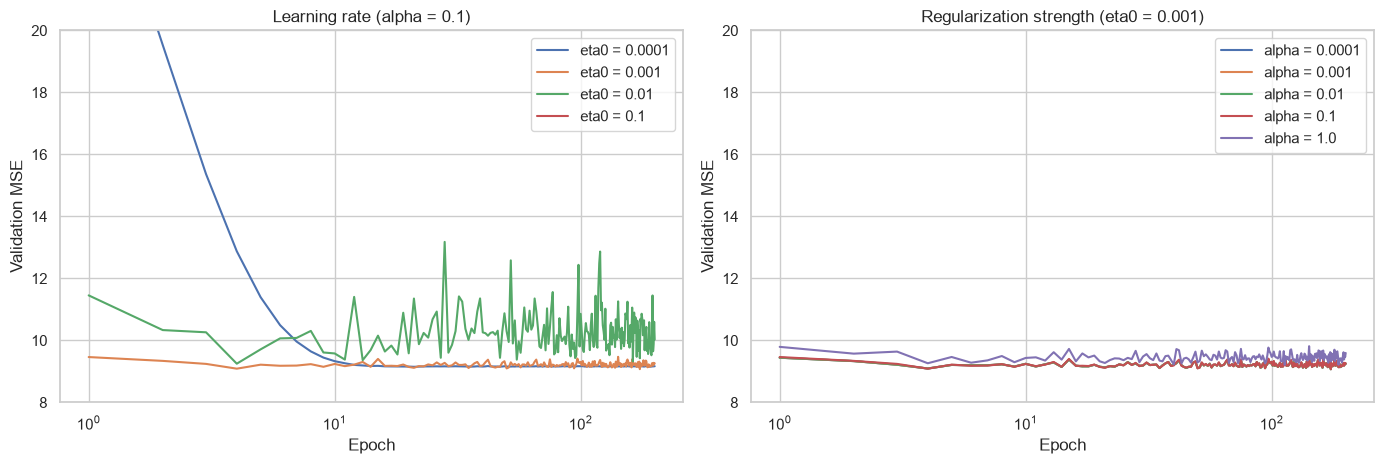

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for eta0 in LEARNING_RATES:
    hist = np.array(histories[(eta0, BEST_ALPHA)], dtype=float)
    hist[~np.isfinite(hist)] = np.nan
    axes[0].plot(range(1, len(hist) + 1), hist, label=f"eta0 = {eta0}")
axes[0].set(title=f"Learning rate (alpha = {BEST_ALPHA})", xlabel="Epoch", ylabel="Validation MSE", xscale="log", ylim=(8, 20))
axes[0].legend()

for alpha in ALPHAS:
    hist = np.array(histories[(BEST_ETA0, alpha)], dtype=float)
    axes[1].plot(range(1, len(hist) + 1), hist, label=f"alpha = {alpha}")
axes[1].set(title=f"Regularization strength (eta0 = {BEST_ETA0})", xlabel="Epoch", ylabel="Validation MSE", xscale="log", ylim=(8, 20))
axes[1].legend()
plt.tight_layout()
plt.show()

**How each hyperparameter changed the loss**

| Hyperparameter | Values tried | Effect on validation MSE | Chosen |
|---|---|---|---|
| Learning rate (`eta0`) | 0.0001 to 0.1 | 0.1 diverged. 0.01 was unstable. 0.0001 was slow. 0.001 was lowest (9.10). | 0.001 |
| Regularization (`alpha`, L2) | 0.0001 to 1.0 | Little effect up to 0.1, because the model is not overfitting. 1.0 underfit (9.29). | 0.1 |
| Epochs | 5 to 200 | Converged within the first epochs. More epochs did not help. | 50 |

### 7.2 Loss curve
The chosen settings are retrained on the full training set for 200 epochs.

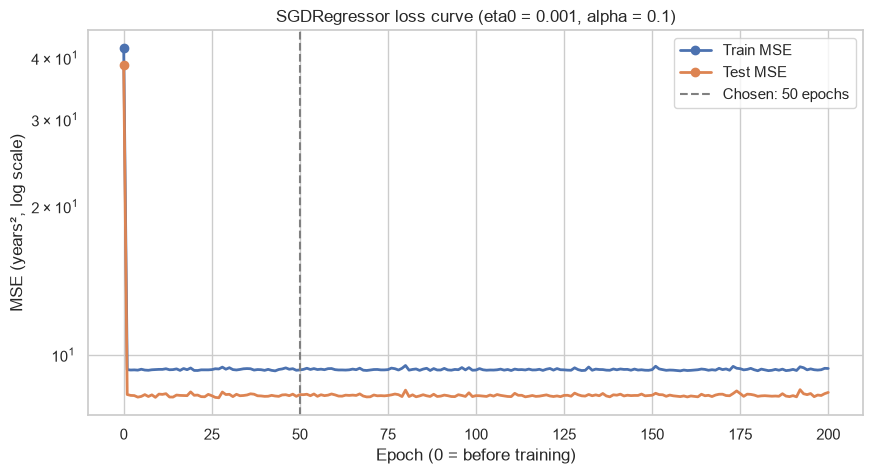

Before training (epoch 0): train MSE 41.902, test MSE 38.624
After 1 epoch: train MSE 9.327, test MSE 8.303
After 50 epochs: train MSE 9.315, test MSE 8.300
After 200 epochs: train MSE 9.377, test MSE 8.385


In [20]:
_, curve_train, curve_test = train_sgd(X_train_t, y_train, X_test_t, y_test, BEST_ETA0, BEST_ALPHA, MAX_EPOCHS)

# Epoch 0 = before any training: all weights are 0, so every prediction is 0
curve_train = [float(np.mean(y_train ** 2))] + curve_train
curve_test = [float(np.mean(y_test ** 2))] + curve_test

fig, ax = plt.subplots(figsize=(10, 5))
epochs_axis = range(0, len(curve_train))
ax.plot(epochs_axis, curve_train, label="Train MSE", linewidth=2, marker="o", markevery=[0])
ax.plot(epochs_axis, curve_test, label="Test MSE", linewidth=2, marker="o", markevery=[0])
ax.axvline(BEST_EPOCHS, color="grey", linestyle="--", label=f"Chosen: {BEST_EPOCHS} epochs")
ax.set_yscale("log")
ax.set(title=f"SGDRegressor loss curve (eta0 = {BEST_ETA0}, alpha = {BEST_ALPHA})",
       xlabel="Epoch (0 = before training)", ylabel="MSE (years², log scale)")
ax.legend()
plt.show()

sgd_model, _, _ = train_sgd(X_train_t, y_train, X_test_t, y_test, BEST_ETA0, BEST_ALPHA, BEST_EPOCHS)
print(f"Before training (epoch 0): train MSE {curve_train[0]:.3f}, test MSE {curve_test[0]:.3f}")
print(f"After 1 epoch: train MSE {curve_train[1]:.3f}, test MSE {curve_test[1]:.3f}")
print(f"After {BEST_EPOCHS} epochs: train MSE {curve_train[BEST_EPOCHS]:.3f}, test MSE {curve_test[BEST_EPOCHS]:.3f}")
print(f"After {MAX_EPOCHS} epochs: train MSE {curve_train[-1]:.3f}, test MSE {curve_test[-1]:.3f}")

**What the loss curve shows:** The MSE drops from 42 to about 9 after one epoch, then stays flat. The train and test curves stay close, so there is no overfitting. Test MSE is slightly lower because the test set has fewer late diagnoses.

## 8. The other three models
* Linear regression (closed form): computes the best weights directly. It checks the SGD result.
* Decision tree: splits the data with yes/no rules. We tune its depth.
* Random forest: averages 300 trees. We tune its depth too.

In [21]:
linear_model = LinearRegression().fit(X_train_t, y_train)

depth_rows = []
for depth in [2, 3, 4, 5, 6, 8, 10, None]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(X_fit, y_fit)
    forest = RandomForestRegressor(n_estimators=300, max_depth=depth, min_samples_leaf=5,
                                   random_state=RANDOM_STATE, n_jobs=-1).fit(X_fit, y_fit)
    depth_rows.append({"max_depth": str(depth),
                       "tree_train_mse": mean_squared_error(y_fit, tree.predict(X_fit)),
                       "tree_val_mse": mean_squared_error(y_val, tree.predict(X_val)),
                       "forest_train_mse": mean_squared_error(y_fit, forest.predict(X_fit)),
                       "forest_val_mse": mean_squared_error(y_val, forest.predict(X_val))})
depth_table = pd.DataFrame(depth_rows)
print(depth_table.round(3).to_string(index=False))

to_depth = lambda value: None if value == "None" else int(value)
TREE_DEPTH = to_depth(depth_table.loc[depth_table["tree_val_mse"].idxmin(), "max_depth"])
FOREST_DEPTH = to_depth(depth_table.loc[depth_table["forest_val_mse"].idxmin(), "max_depth"])
print(f"\nChosen max_depth: decision tree = {TREE_DEPTH}, random forest = {FOREST_DEPTH}")

tree_model = DecisionTreeRegressor(max_depth=TREE_DEPTH, random_state=RANDOM_STATE).fit(X_train_t, y_train)
forest_model = RandomForestRegressor(n_estimators=300, max_depth=FOREST_DEPTH, min_samples_leaf=5,
                                     random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_t, y_train)

max_depth  tree_train_mse  tree_val_mse  forest_train_mse  forest_val_mse
        2          10.409        10.125            10.107           9.909
        3           9.620         9.492             9.366           9.353
        4           9.219         9.247             8.982           9.082
        5           8.847         9.611             8.566           9.032
        6           8.362         9.988             8.104           9.075
        8           7.034        11.139             7.357           9.148
       10           5.647        12.542             6.996           9.185
     None           2.834        15.499             6.881           9.211

Chosen max_depth: decision tree = 4, random forest = 5


**What the depth search shows:** The single tree overfits beyond depth 4. The forest stays stable, because averaging 300 trees cancels much of the noise. We use depth 4 for the tree and depth 5 for the forest.

## 9. Comparison of the four models
All models are scored on the same 795 test children. The baseline always predicts the mean.

In [22]:
models = {
    "Linear regression (SGD, gradient descent)": sgd_model,
    "Linear regression (closed form)": linear_model,
    "Decision tree": tree_model,
    "Random forest": forest_model,
}

baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
rows = [{"Model": "Baseline (predict the mean)",
         "Train MSE": mean_squared_error(y_train, np.full(len(y_train), y_train.mean())),
         "Test MSE": baseline_mse}]
for name, model in models.items():
    rows.append({"Model": name,
                 "Train MSE": mean_squared_error(y_train, model.predict(X_train_t)),
                 "Test MSE": mean_squared_error(y_test, model.predict(X_test_t))})

comparison = pd.DataFrame(rows)
comparison["Test RMSE (years)"] = np.sqrt(comparison["Test MSE"])
comparison["RMSE vs baseline"] = (1 - comparison["Test RMSE (years)"] / np.sqrt(baseline_mse)).map("{:.1%} lower".format)
comparison = comparison.sort_values("Test MSE").reset_index(drop=True)
comparison.round(3)

,Model,Train MSE,Test MSE,Test RMSE (years),RMSE vs baseline
0,Random forest,8.641,7.858,2.803,19.8% lower
1,Linear regression (closed form),9.262,8.215,2.866,18.0% lower
2,Decision tree,9.214,8.285,2.878,17.7% lower
3,"Linear regression (SGD, gradient descent)",9.315,8.300,2.881,17.6% lower
4,Baseline (predict the mean),13.501,12.217,3.495,0.0% lower


Best model (lowest test MSE): Random forest  -> test MSE 7.858, RMSE 2.80 years


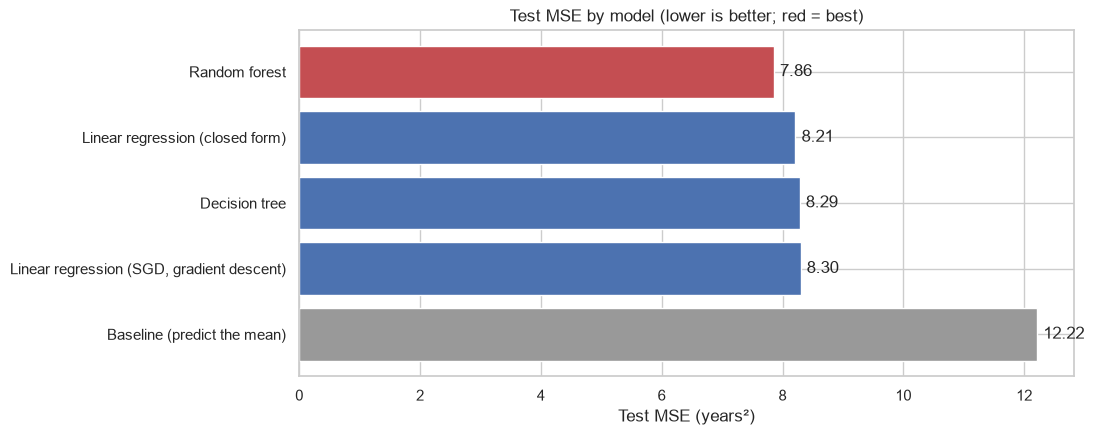

In [23]:
model_rows = comparison[comparison["Model"] != "Baseline (predict the mean)"]
BEST_MODEL_NAME = model_rows.iloc[0]["Model"]
best_model = models[BEST_MODEL_NAME]
print(f"Best model (lowest test MSE): {BEST_MODEL_NAME}  -> test MSE {model_rows.iloc[0]['Test MSE']:.3f}, "
      f"RMSE {model_rows.iloc[0]['Test RMSE (years)']:.2f} years")

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_data = comparison.sort_values("Test MSE", ascending=False)
colors = ["#C44E52" if m == BEST_MODEL_NAME else ("#999999" if m.startswith("Baseline") else "#4C72B0") for m in plot_data["Model"]]
ax.barh(plot_data["Model"], plot_data["Test MSE"], color=colors)
for y_pos, value in enumerate(plot_data["Test MSE"]):
    ax.text(value + 0.1, y_pos, f"{value:.2f}", va="center")
ax.set(title="Test MSE by model (lower is better; red = best)", xlabel="Test MSE (years²)")
plt.show()

**Best model:** Random forest. It has the lowest test MSE (7.86). Its RMSE of 2.80 years is 19.8% better than the baseline.

**How the dataset affected each model**
* Linear regression (closed form, 8.21) and SGD (8.30): the same model fitted two ways. They cannot capture combinations of conditions.
* Decision tree (8.29): captures combinations, but its predictions are coarse.
* Random forest (7.86): captures combinations without overfitting. Train and test MSE are close.

**Why it is the right choice for the problem:** It makes the smallest errors on unseen children, which outreach teams need. The remaining error comes from factors the survey does not record, such as waiting lists.

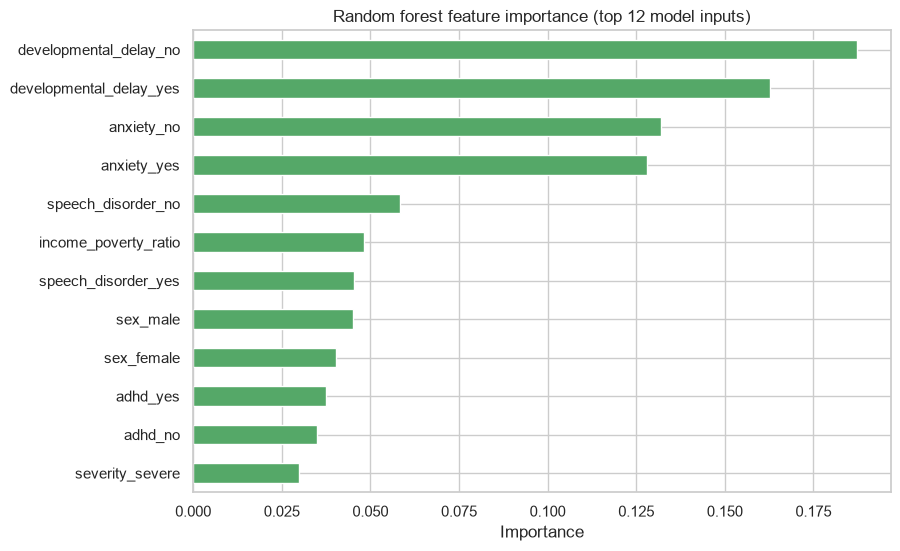

In [24]:
importances = pd.Series(forest_model.feature_importances_, index=preprocessor.get_feature_names_out())
importances.index = importances.index.str.replace("num__", "").str.replace("cat__", "")
fig, ax = plt.subplots(figsize=(9, 6))
importances.sort_values().tail(12).plot.barh(ax=ax, color="#55A868")
ax.set(title="Random forest feature importance (top 12 model inputs)", xlabel="Importance")
plt.show()

**What it shows:** The forest relies most on developmental delay and anxiety, then speech disorder, income, sex, ADHD and severity. This matches the heatmap. Income ranks high partly because forests favour continuous features.

## 10. Scatter plots: before and after fitting a line
`developmental_delay` is the kept feature most correlated with the target (r = -0.38). Small jitter separates the yes/no points.

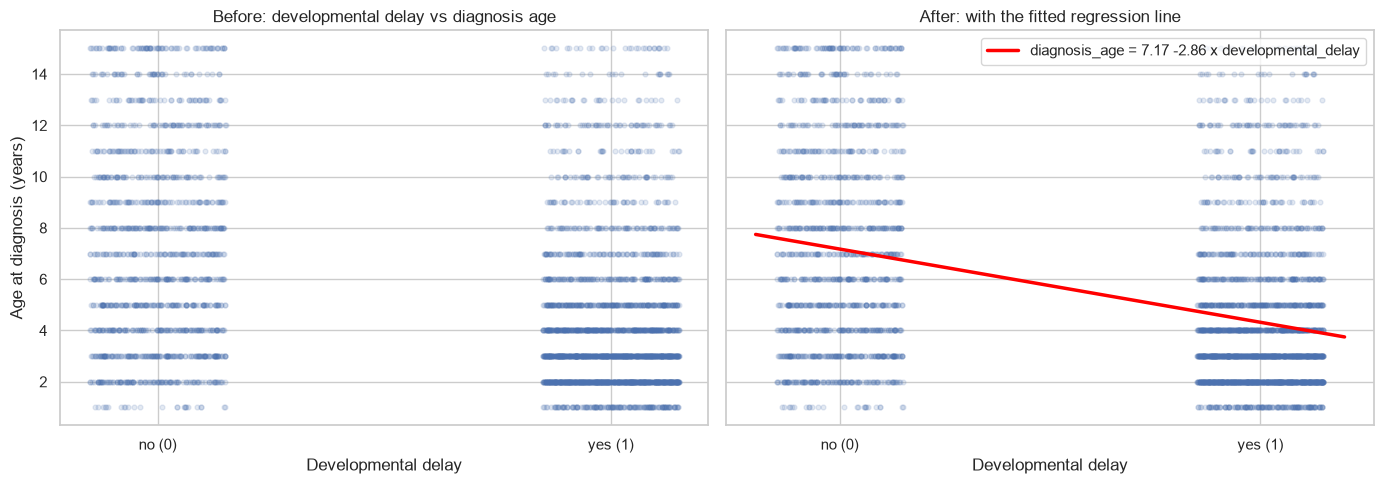

In [25]:
top_feature = "developmental_delay"
x_all = (df[top_feature] == "yes").astype(float)
y_all = df[TARGET]
mask = df[top_feature].notna()
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.15, 0.15, mask.sum())

one_feature = LinearRegression().fit(x_all[train_rows].to_frame(), y_all[train_rows])
line_x = np.linspace(-0.2, 1.2, 50)
line_y = one_feature.intercept_ + one_feature.coef_[0] * line_x

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, with_line in zip(axes, [False, True]):
    ax.scatter(x_all[mask] + jitter, y_all[mask], alpha=0.15, s=12, color="#4C72B0")
    if with_line:
        ax.plot(line_x, line_y, color="red", linewidth=2.5,
                label=f"diagnosis_age = {one_feature.intercept_:.2f} {one_feature.coef_[0]:+.2f} x developmental_delay")
        ax.legend(loc="upper right")
    ax.set(xticks=[0, 1], xticklabels=["no (0)", "yes (1)"], xlabel="Developmental delay",
           title="After: with the fitted regression line" if with_line else "Before: developmental delay vs diagnosis age")
axes[0].set_ylabel("Age at diagnosis (years)")
plt.tight_layout()
plt.show()

**What it shows:** The line is diagnosis_age = 7.17 - 2.86 x developmental_delay. Children with a delay are diagnosed about 2.9 years earlier. The wide spread shows one feature is not enough, so the models use all 10.

## 11. Save the best model
The random forest is saved with its preprocessing as one `Pipeline`. It also stores its training and test rows, so the API can retrain on new data.

In [26]:
import os
import joblib

MODEL_PATH = "../API/best_model.pkl"
best_pipeline = Pipeline([("preprocess", preprocessor), ("model", best_model)])
best_pipeline.training_data_ = pd.concat([X_train, y_train], axis=1).reset_index(drop=True)
best_pipeline.test_data_ = pd.concat([X_test, y_test], axis=1).reset_index(drop=True)
joblib.dump(best_pipeline, MODEL_PATH, compress=3)

print(f"Saved {BEST_MODEL_NAME} pipeline to {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1024:.0f} KB)")
print("Test MSE of the saved pipeline on raw test data:", round(mean_squared_error(y_test, best_pipeline.predict(X_test)), 3))

Saved Random forest pipeline to ../API/best_model.pkl (449 KB)
Test MSE of the saved pipeline on raw test data: 7.858


## 12. Predict for one row of the test set
`predict_diagnosis_age` loads the saved model and predicts for one child. The API reuses it.

In [27]:
def predict_diagnosis_age(child, model_path=MODEL_PATH):
    """Load the saved pipeline and predict the age at autism diagnosis (years) for one child.

    child: a one-row DataFrame, or a dict, with the 10 input features.
    """
    model = joblib.load(model_path)
    row = pd.DataFrame([child]) if isinstance(child, dict) else child
    return float(model.predict(row[FEATURES])[0])


complete_test_rows = X_test.dropna()          # the API always receives all 10 values
one_child = complete_test_rows.iloc[[0]]
actual_age = y_test.loc[one_child.index[0]]
predicted_age = predict_diagnosis_age(one_child)

print("Input (first complete row of the test set):")
print(one_child.T.to_string(header=False))
print(f"\nPredicted age at diagnosis: {predicted_age:.1f} years")
print(f"Actual age at diagnosis:    {actual_age:.0f} years")
print(f"Error:                      {predicted_age - actual_age:+.1f} years")

Input (first complete row of the test set):
income_poverty_ratio                     50
severity                           moderate
adhd                                    yes
anxiety                                 yes
developmental_delay                      no
speech_disorder                          no
intellectual_disability                  no
sex                                    male
insurance_type           public_and_private
home_language                       english

Predicted age at diagnosis: 6.8 years
Actual age at diagnosis:    4 years
Error:                      +2.8 years


The model predicts 6.8 years; the actual age was 4. The 2.8-year error matches the model's typical error. ADHD and anxiety without a delay pushed the prediction later, so this family would be flagged for early outreach.